# PlantVillage — Plant Disease Classification Using 10 Machine Learning Algorithms

**Laptop-friendly configuration:** 8 GB RAM, AMD Ryzen 5  
**Dataset:** PlantVillage `D:\\raw\\color` RGB images  
**Approach:** HOG + RGB colour histogram features, PCA dimensionality reduction, and 10 classical ML classifiers.

This notebook is organized block by block, like the original notebook. Start with 40 images per class and 96×96 image size. Once the workflow completes reliably, increase the image limit gradually.

> **Important:** This is a quick, laptop-friendly experimental setup. It uses a stratified image-level split. For research-grade evaluation, use `leaf_grouping` metadata to keep images from the same leaf in only one split, if available and mapped to filenames. Do not describe the 40-per-class subset as the full PlantVillage dataset.

## Block 1 — Install and import required libraries

In [1]:
# Run this cell first after restarting the Jupyter kernel.
# Optional installation:
# %pip install numpy pandas matplotlib seaborn scikit-learn scikit-image pillow joblib tqdm

# Windows Joblib / Loky CPU detection workaround.
# Set these BEFORE importing scikit-learn and joblib.
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "2"
os.environ["JOBLIB_MULTIPROCESSING"] = "0"

import time
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFile
from tqdm.auto import tqdm
from skimage.feature import hog
from skimage.color import rgb2gray

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from sklearn.linear_model import LogisticRegression, SGDClassifier, PassiveAggressiveClassifier
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.decomposition import PCA
from sklearn.base import clone
import joblib

warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = True
RANDOM_STATE = 42

print("Libraries imported successfully.")
print("Joblib CPU limit:", os.environ["LOKY_MAX_CPU_COUNT"])

Libraries imported successfully.
Joblib CPU limit: 2


## Block 2 — Set the dataset folder

In [2]:
# Dataset folder: D:\\raw\\color
DATASET_DIR = Path(r"D:\\raw\\color")

# Start with 40 images per class for a faster first experiment.
# Increase to 60, 100, or None after confirming that the notebook runs.
MAX_IMAGES_PER_CLASS = 40

# Smaller images reduce feature extraction time and memory usage.
IMAGE_SIZE = (96, 96)

SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATASET_DIR}\n"
        "Check that your folder structure is D:\\raw\\color\\class_name."
    )

print("Dataset directory:", DATASET_DIR)
print("Images per class:", MAX_IMAGES_PER_CLASS)
print("Image size:", IMAGE_SIZE)

Dataset directory: D:\raw\color
Images per class: 40
Image size: (96, 96)


## Block 3 — Discover image classes and files

In [3]:
class_folders = sorted([p for p in DATASET_DIR.iterdir() if p.is_dir()])
if not class_folders:
    raise ValueError("No class subfolders found. Expected one folder per disease class.")

records = []
for class_folder in class_folders:
    image_paths = [
        p for p in class_folder.rglob("*")
        if p.is_file() and p.suffix.lower() in SUPPORTED_EXTENSIONS
    ]
    image_paths = sorted(image_paths)
    if MAX_IMAGES_PER_CLASS is not None:
        image_paths = image_paths[:MAX_IMAGES_PER_CLASS]
    for image_path in image_paths:
        records.append({"image_path": str(image_path), "label": class_folder.name})

image_df = pd.DataFrame(records)
if image_df.empty:
    raise ValueError("No images found. Check folder structure and supported file extensions.")

print("Total images selected:", len(image_df))
print("Number of classes:", image_df["label"].nunique())
display(image_df.head())
display(image_df["label"].value_counts().rename("image_count").to_frame())

Total images selected: 1520
Number of classes: 38


,image_path,label
0,D:\raw\color\Apple___Apple_scab\00075aa8-d81a-...,Apple___Apple_scab
1,D:\raw\color\Apple___Apple_scab\01a66316-0e98-...,Apple___Apple_scab
2,D:\raw\color\Apple___Apple_scab\01f3deaa-6143-...,Apple___Apple_scab
3,D:\raw\color\Apple___Apple_scab\0208f4eb-45a4-...,Apple___Apple_scab
4,D:\raw\color\Apple___Apple_scab\023123cb-7b69-...,Apple___Apple_scab


,image_count
label,
Apple___Apple_scab,40
Apple___Black_rot,40
Apple___Cedar_apple_rust,40
Apple___healthy,40
Blueberry___healthy,40
Cherry_(including_sour)___healthy,40
Cherry_(including_sour)___Powdery_mildew,40
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,40
Corn_(maize)___Common_rust_,40


## Block 4 — Visualise class distribution

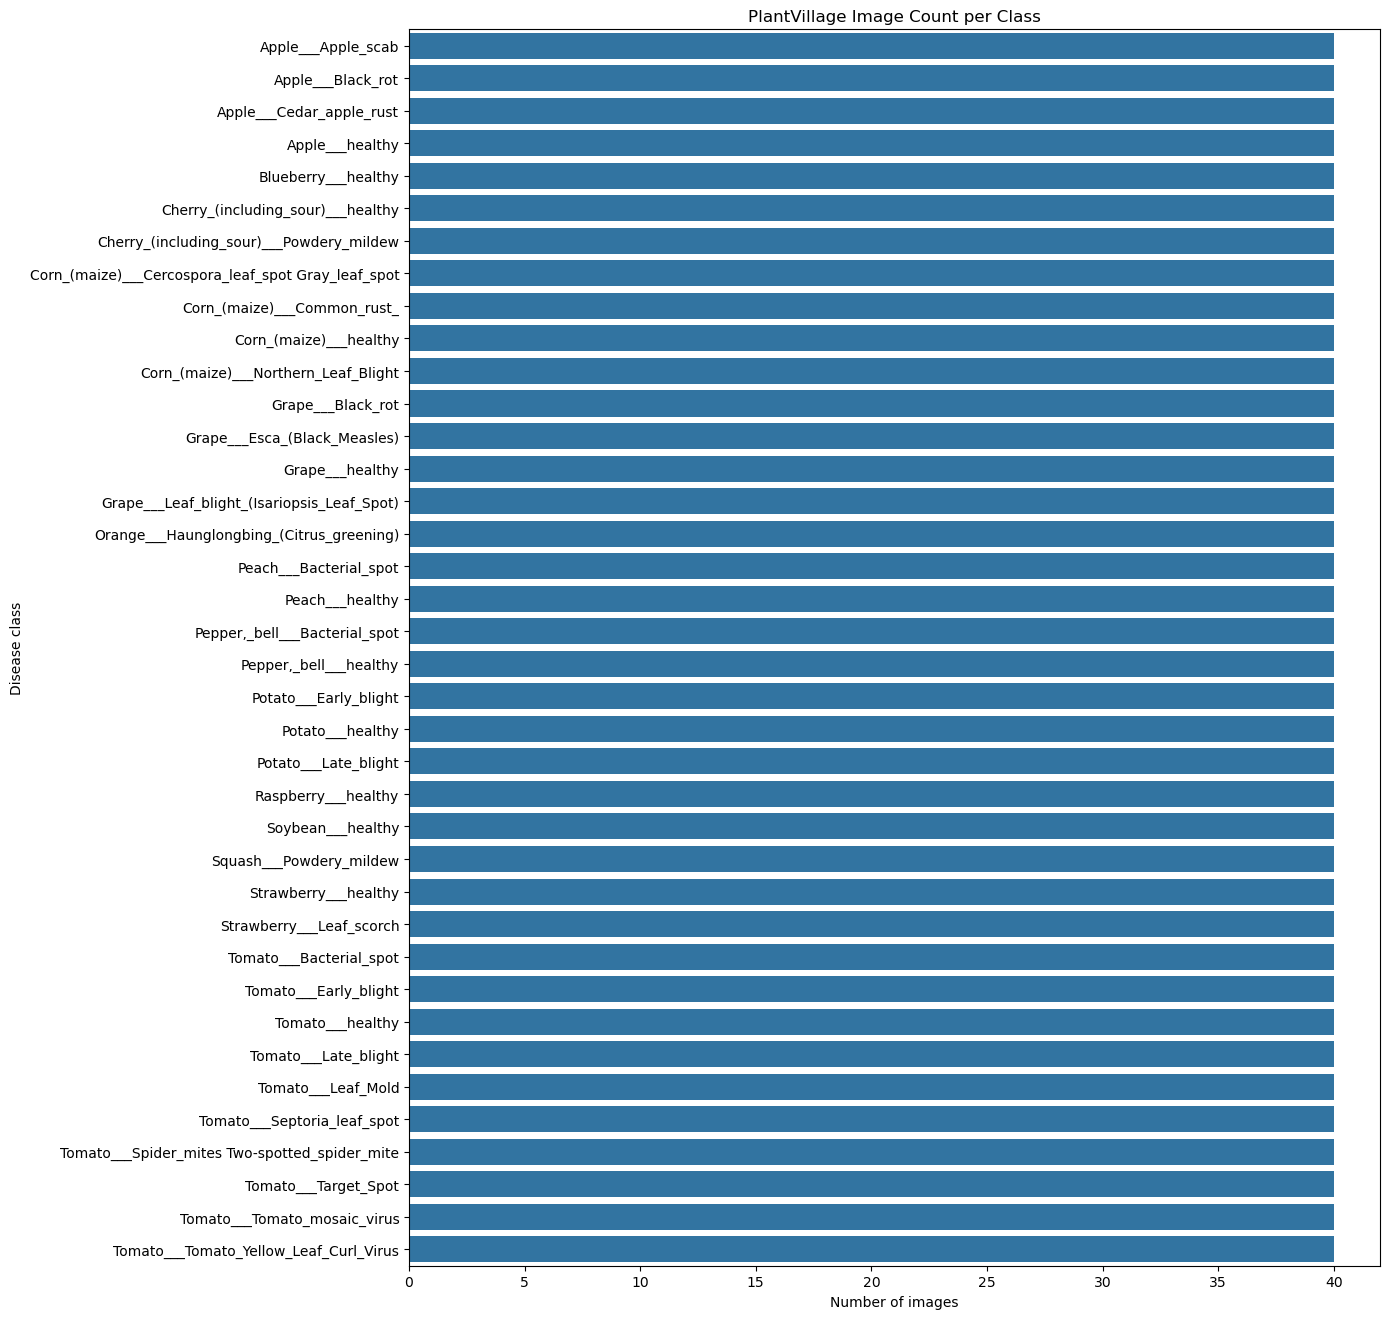

In [4]:
class_counts = image_df["label"].value_counts().sort_values(ascending=False)
plt.figure(figsize=(14, max(6, len(class_counts) * 0.35)))
sns.barplot(x=class_counts.values, y=class_counts.index)
plt.title("PlantVillage Image Count per Class")
plt.xlabel("Number of images")
plt.ylabel("Disease class")
plt.tight_layout()
plt.show()

## Block 5 — Display sample images

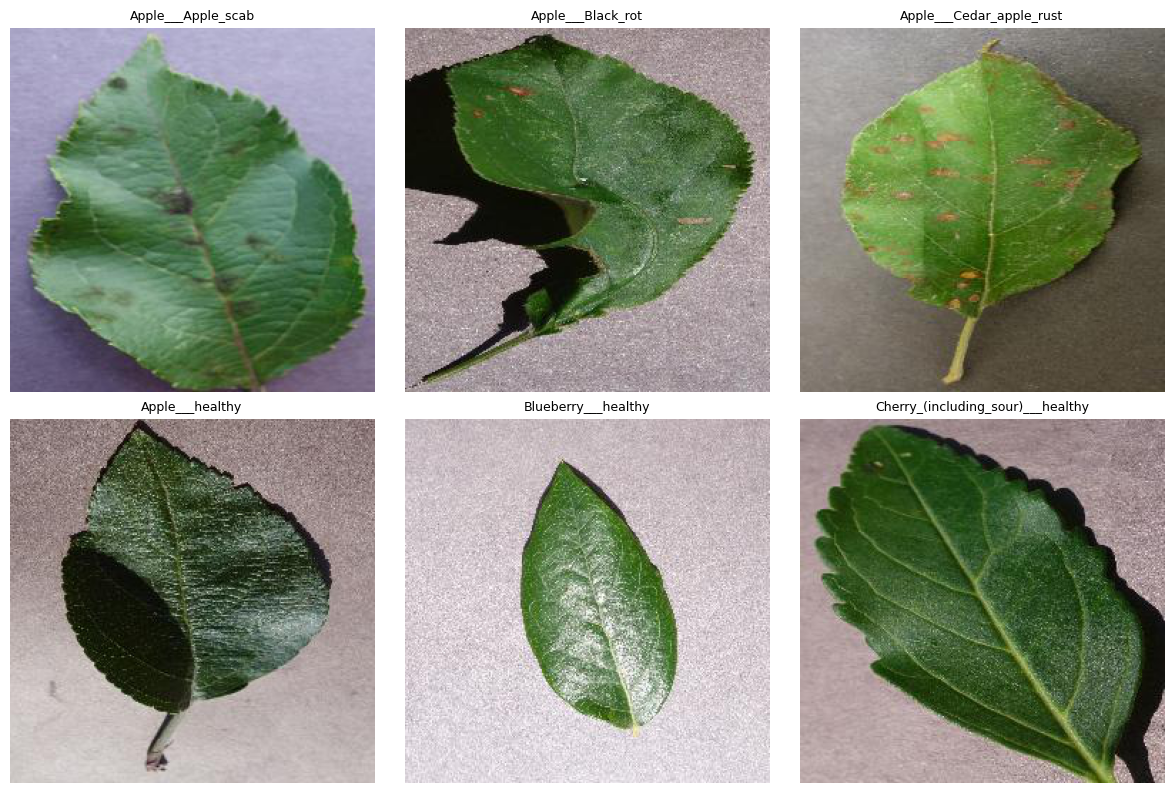

In [5]:
sample_classes = image_df["label"].drop_duplicates().head(6).tolist()
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, class_name in zip(axes.ravel(), sample_classes):
    sample_path = image_df.loc[image_df["label"] == class_name, "image_path"].iloc[0]
    img = Image.open(sample_path).convert("RGB")
    ax.imshow(img)
    ax.set_title(class_name, fontsize=9)
    ax.axis("off")
for ax in axes.ravel()[len(sample_classes):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Block 6 — Define image feature extraction (HOG + colour histogram)

In [6]:
def extract_image_features(image_path, image_size=IMAGE_SIZE):
    """Convert an RGB leaf image into HOG and RGB colour-histogram features."""
    try:
        image = Image.open(image_path).convert("RGB").resize(image_size)
        rgb = np.asarray(image, dtype=np.uint8)

        gray = rgb2gray(rgb)
        hog_features = hog(
            gray,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm="L2-Hys",
            feature_vector=True
        )

        colour_features = []
        for channel in range(3):
            hist, _ = np.histogram(
                rgb[:, :, channel], bins=32, range=(0, 256), density=True
            )
            colour_features.extend(hist)

        return np.concatenate([hog_features, np.asarray(colour_features, dtype=np.float32)])
    except Exception as exc:
        print(f"Could not process {image_path}: {exc}")
        return None

print("Feature extraction function is ready.")

Feature extraction function is ready.


## Block 7 — Extract features from all selected images

In [7]:
feature_rows = []
valid_labels = []
valid_paths = []

for row in tqdm(image_df.itertuples(index=False), total=len(image_df), desc="Extracting features"):
    features = extract_image_features(row.image_path)
    if features is not None:
        feature_rows.append(features)
        valid_labels.append(row.label)
        valid_paths.append(row.image_path)

X = np.asarray(feature_rows, dtype=np.float32)
y_text = np.asarray(valid_labels)

print("Feature matrix shape:", X.shape)
print("Labels shape:", y_text.shape)
print("Images successfully processed:", len(valid_paths))

Extracting features:   0%|          | 0/1520 [00:00<?, ?it/s]

Feature matrix shape: (1520, 4452)
Labels shape: (1520,)
Images successfully processed: 1520


## Block 8 — Encode target labels

In [8]:
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)

class_names = label_encoder.classes_
print("Number of encoded classes:", len(class_names))
print("Classes:", list(class_names))

Number of encoded classes: 38
Classes: [np.str_('Apple___Apple_scab'), np.str_('Apple___Black_rot'), np.str_('Apple___Cedar_apple_rust'), np.str_('Apple___healthy'), np.str_('Blueberry___healthy'), np.str_('Cherry_(including_sour)___Powdery_mildew'), np.str_('Cherry_(including_sour)___healthy'), np.str_('Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot'), np.str_('Corn_(maize)___Common_rust_'), np.str_('Corn_(maize)___Northern_Leaf_Blight'), np.str_('Corn_(maize)___healthy'), np.str_('Grape___Black_rot'), np.str_('Grape___Esca_(Black_Measles)'), np.str_('Grape___Leaf_blight_(Isariopsis_Leaf_Spot)'), np.str_('Grape___healthy'), np.str_('Orange___Haunglongbing_(Citrus_greening)'), np.str_('Peach___Bacterial_spot'), np.str_('Peach___healthy'), np.str_('Pepper,_bell___Bacterial_spot'), np.str_('Pepper,_bell___healthy'), np.str_('Potato___Early_blight'), np.str_('Potato___Late_blight'), np.str_('Potato___healthy'), np.str_('Raspberry___healthy'), np.str_('Soybean___healthy'), np.str_('Squ

## Block 9 — Split into training, validation and test sets

In [9]:
# 70% training, 15% validation, 15% testing.
# Stratification keeps class proportions similar in each split.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

print("Training:", X_train.shape, "Validation:", X_val.shape, "Testing:", X_test.shape)
print("Split percentages:",
      round(len(X_train)/len(X)*100, 1),
      round(len(X_val)/len(X)*100, 1),
      round(len(X_test)/len(X)*100, 1))

Training: (1064, 4452) Validation: (228, 4452) Testing: (228, 4452)
Split percentages: 70.0 15.0 15.0


## Block 10 — Define exactly 10 lightweight ML algorithms

In [10]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=300, random_state=RANDOM_STATE
    ),

    "Linear SVM": LinearSVC(
        max_iter=1500, random_state=RANDOM_STATE
    ),

    "SGD Classifier": SGDClassifier(
        max_iter=500, random_state=RANDOM_STATE
    ),

    "Passive Aggressive": PassiveAggressiveClassifier(
        max_iter=500, random_state=RANDOM_STATE
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=15, random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=40, max_depth=15,
        n_jobs=1, random_state=RANDOM_STATE
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=40, max_depth=15,
        n_jobs=1, random_state=RANDOM_STATE
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=3, n_jobs=1
    ),

    "Gaussian Naive Bayes": GaussianNB(),

    "AdaBoost": AdaBoostClassifier(
        n_estimators=20, random_state=RANDOM_STATE
    )
}

print("Total ML algorithms:", len(models))
for name in models:
    print("-", name)

Total ML algorithms: 10
- Logistic Regression
- Linear SVM
- SGD Classifier
- Passive Aggressive
- Decision Tree
- Random Forest
- Extra Trees
- K-Nearest Neighbors
- Gaussian Naive Bayes
- AdaBoost


## Block 11 — Train 10 models and compare validation performance

In [11]:
# Scale and reduce features ONCE, rather than repeating this work for every model.
# PCA is fitted only on training data to avoid validation/test leakage.

print("Scaling training and validation features...")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print("Applying PCA...")
PCA_COMPONENTS = min(100, X_train_scaled.shape[0], X_train_scaled.shape[1])

pca = PCA(
    n_components=PCA_COMPONENTS,
    svd_solver="randomized",
    random_state=RANDOM_STATE
)

X_train_pca = pca.fit_transform(X_train_scaled)
X_val_pca = pca.transform(X_val_scaled)

print("Original feature count:", X_train.shape[1])
print("Reduced feature count:", X_train_pca.shape[1])
print("Explained variance ratio:", round(float(pca.explained_variance_ratio_.sum()), 4))

# Train and validate each classifier.
validation_results = []
trained_models = {}

for name, estimator in models.items():
    print(f"\\nTraining: {name}", flush=True)
    start_time = time.time()

    estimator.fit(X_train_pca, y_train)
    training_seconds = time.time() - start_time

    val_pred = estimator.predict(X_val_pca)

    validation_results.append({
        "Model": name,
        "Validation Accuracy": accuracy_score(y_val, val_pred),
        "Validation Precision (weighted)": precision_score(
            y_val, val_pred, average="weighted", zero_division=0
        ),
        "Validation Recall (weighted)": recall_score(
            y_val, val_pred, average="weighted", zero_division=0
        ),
        "Validation F1 (weighted)": f1_score(
            y_val, val_pred, average="weighted", zero_division=0
        ),
        "Training Time (sec)": round(training_seconds, 2)
    })

    trained_models[name] = estimator
    print(f"Completed: {name} | Time: {training_seconds:.2f} seconds", flush=True)

validation_df = pd.DataFrame(validation_results).sort_values(
    "Validation F1 (weighted)", ascending=False
).reset_index(drop=True)

display(validation_df.style.format({
    "Validation Accuracy": "{:.4f}",
    "Validation Precision (weighted)": "{:.4f}",
    "Validation Recall (weighted)": "{:.4f}",
    "Validation F1 (weighted)": "{:.4f}",
    "Training Time (sec)": "{:.2f}"
}))

Scaling training and validation features...
Applying PCA...
Original feature count: 4452
Reduced feature count: 100
Explained variance ratio: 0.5171
\nTraining: Logistic Regression
Completed: Logistic Regression | Time: 0.21 seconds
\nTraining: Linear SVM
Completed: Linear SVM | Time: 3.70 seconds
\nTraining: SGD Classifier
Completed: SGD Classifier | Time: 0.16 seconds
\nTraining: Passive Aggressive
Completed: Passive Aggressive | Time: 0.36 seconds
\nTraining: Decision Tree
Completed: Decision Tree | Time: 0.30 seconds
\nTraining: Random Forest
Completed: Random Forest | Time: 0.75 seconds
\nTraining: Extra Trees
Completed: Extra Trees | Time: 0.20 seconds
\nTraining: K-Nearest Neighbors
Completed: K-Nearest Neighbors | Time: 0.00 seconds
\nTraining: Gaussian Naive Bayes
Completed: Gaussian Naive Bayes | Time: 0.00 seconds
\nTraining: AdaBoost
Completed: AdaBoost | Time: 0.48 seconds


,Model,Validation Accuracy,Validation Precision (weighted),Validation Recall (weighted),Validation F1 (weighted),Training Time (sec)
0,Logistic Regression,0.4561,0.4732,0.4561,0.4544,0.21
1,Gaussian Naive Bayes,0.3904,0.4294,0.3904,0.3689,0.00
2,SGD Classifier,0.3728,0.3895,0.3728,0.3673,0.16
3,Random Forest,0.3553,0.3529,0.3553,0.3353,0.75
4,Passive Aggressive,0.3553,0.3505,0.3553,0.3270,0.36
5,Linear SVM,0.3377,0.3306,0.3377,0.3200,3.70
6,K-Nearest Neighbors,0.3202,0.3253,0.3202,0.2987,0.00
7,Extra Trees,0.2982,0.3120,0.2982,0.2862,0.20
8,Decision Tree,0.1535,0.1558,0.1535,0.1460,0.30
9,AdaBoost,0.0746,0.0281,0.0746,0.0351,0.48


## Block 12 — Plot validation model comparison

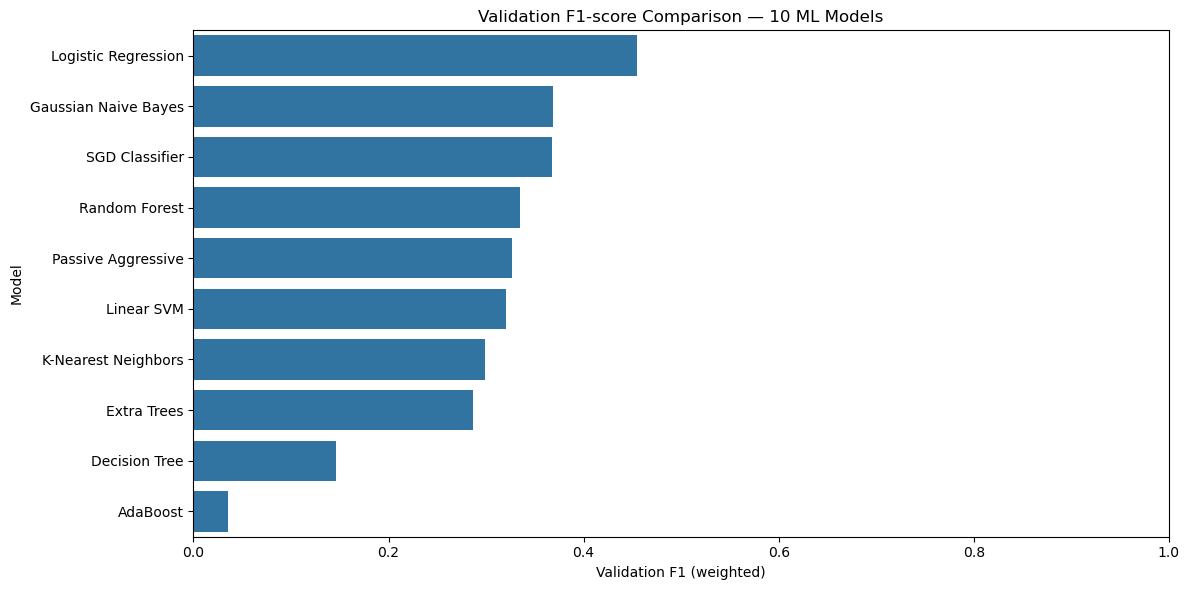

In [12]:
plt.figure(figsize=(12, 6))
sns.barplot(data=validation_df, x="Validation F1 (weighted)", y="Model")
plt.title("Validation F1-score Comparison — 10 ML Models")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

## Block 13 — Select the best model using validation F1-score

In [13]:
best_model_name = validation_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model selected using validation data:", best_model_name)
print("Validation F1-score:",
      round(validation_df.iloc[0]["Validation F1 (weighted)"], 4))

Best model selected using validation data: Logistic Regression
Validation F1-score: 0.4544


## Block 14 — Refit the selected model on training + validation data

In [14]:
# The test set remains untouched until final evaluation.
X_development = np.concatenate([X_train, X_val], axis=0)
y_development = np.concatenate([y_train, y_val], axis=0)

# Final pipeline accepts raw extracted features and performs scaling + PCA itself.
final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(
        n_components=min(100, X_development.shape[0], X_development.shape[1]),
        svd_solver="randomized",
        random_state=RANDOM_STATE
    )),
    ("classifier", clone(models[best_model_name]))
])

print("Selected model:", best_model_name)
final_model.fit(X_development, y_development)
print("Selected model retrained on combined training + validation data.")

Selected model: Logistic Regression
Selected model retrained on combined training + validation data.


## Block 15 — Final evaluation on the test set

In [15]:
test_pred = final_model.predict(X_test)

test_accuracy = accuracy_score(y_test, test_pred)
test_precision = precision_score(y_test, test_pred, average="weighted", zero_division=0)
test_recall = recall_score(y_test, test_pred, average="weighted", zero_division=0)
test_f1 = f1_score(y_test, test_pred, average="weighted", zero_division=0)

final_test_results = pd.DataFrame([{
    "Best Model": best_model_name,
    "Test Accuracy": test_accuracy,
    "Test Precision (weighted)": test_precision,
    "Test Recall (weighted)": test_recall,
    "Test F1-score (weighted)": test_f1
}])
display(final_test_results.style.format({
    "Test Accuracy": "{:.4f}",
    "Test Precision (weighted)": "{:.4f}",
    "Test Recall (weighted)": "{:.4f}",
    "Test F1-score (weighted)": "{:.4f}"
}))

,Best Model,Test Accuracy,Test Precision (weighted),Test Recall (weighted),Test F1-score (weighted)
0,Logistic Regression,0.4693,0.4953,0.4693,0.4705


## Block 16 — Classification report

In [16]:
print(classification_report(
    y_test, test_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.67      0.67      0.67         6
                                 Apple___Black_rot       0.50      0.83      0.62         6
                          Apple___Cedar_apple_rust       0.33      0.33      0.33         6
                                   Apple___healthy       0.14      0.17      0.15         6
                               Blueberry___healthy       1.00      0.67      0.80         6
          Cherry_(including_sour)___Powdery_mildew       0.33      0.17      0.22         6
                 Cherry_(including_sour)___healthy       0.50      0.33      0.40         6
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.43      0.50      0.46         6
                       Corn_(maize)___Common_rust_       1.00      0.67      0.80         6
               Corn_(maize)___Northern_Leaf_Blight       0.50      0.50      0.

## Block 17 — Confusion matrix

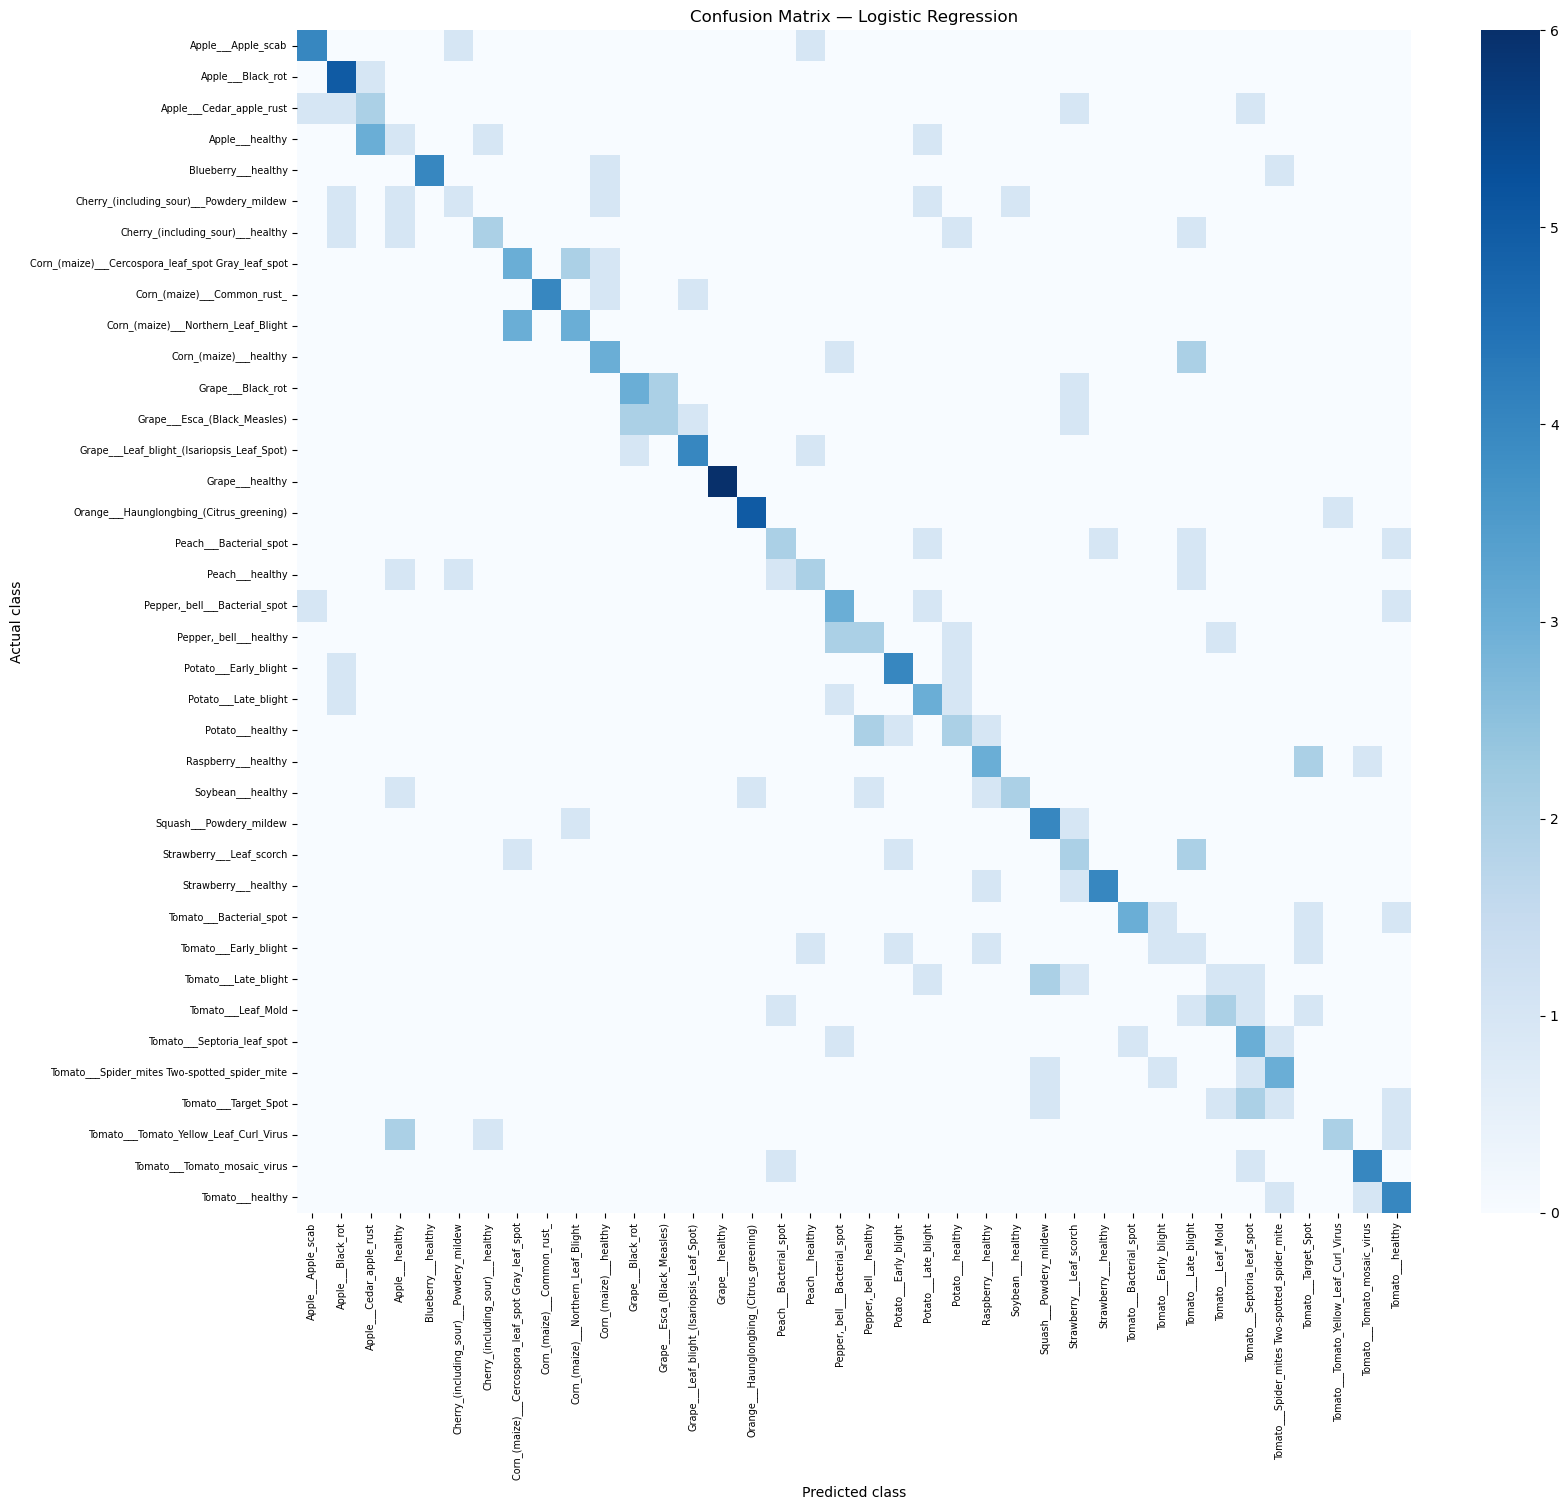

In [17]:
cm = confusion_matrix(y_test, test_pred, labels=np.arange(len(class_names)))
plt.figure(figsize=(max(12, len(class_names)*0.45), max(10, len(class_names)*0.4)))
sns.heatmap(cm, cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()
plt.show()

## Block 18 — Compare validation metrics in one chart

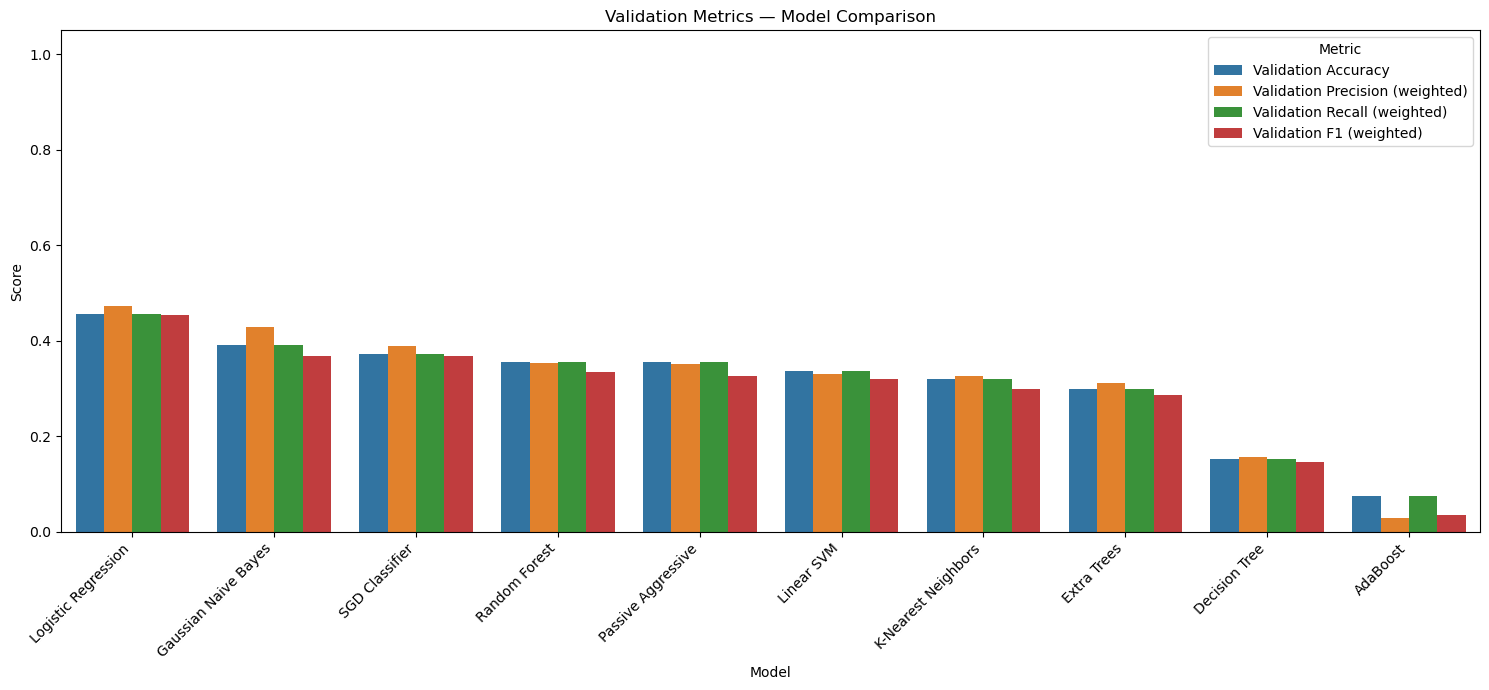

In [18]:
metric_cols = [
    "Validation Accuracy", "Validation Precision (weighted)",
    "Validation Recall (weighted)", "Validation F1 (weighted)"
]
plot_df = validation_df.melt(
    id_vars="Model", value_vars=metric_cols,
    var_name="Metric", value_name="Score"
)
plt.figure(figsize=(15, 7))
sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric")
plt.title("Validation Metrics — Model Comparison")
plt.ylim(0, 1.05)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Block 19 — Save models, encoders and result files

In [19]:
OUTPUT_DIR = Path("plantvillage_ml_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

joblib.dump(final_model, OUTPUT_DIR / "best_plant_disease_model.joblib")
joblib.dump(label_encoder, OUTPUT_DIR / "label_encoder.joblib")

validation_df.to_csv(OUTPUT_DIR / "validation_model_comparison.csv", index=False)
final_test_results.to_csv(OUTPUT_DIR / "final_test_results.csv", index=False)

with open(OUTPUT_DIR / "class_names.json", "w", encoding="utf-8") as f:
    json.dump(list(class_names), f, indent=2)

print("Saved output files in:", OUTPUT_DIR.resolve())
print("Files:", [p.name for p in OUTPUT_DIR.iterdir()])

Saved output files in: C:\Users\Pranav\plantvillage_ml_outputs
Files: ['best_plant_disease_model.joblib', 'class_names.json', 'final_test_results.csv', 'label_encoder.joblib', 'validation_model_comparison.csv']


## Block 20 — Predict the disease class for a new leaf image

In [20]:
def predict_leaf_disease(image_path):
    features = extract_image_features(image_path).reshape(1, -1)
    predicted_encoded = final_model.predict(features)[0]
    predicted_class = label_encoder.inverse_transform([predicted_encoded])[0]

    # Show confidence only if the classifier supports predict_proba.
    classifier = final_model.named_steps["classifier"]
    confidence = None
    if hasattr(final_model, "predict_proba"):
        confidence = float(np.max(final_model.predict_proba(features)))

    return predicted_class, confidence

# Replace with the path to a new leaf image.
NEW_IMAGE_PATH = r"D:\path\to\your\new_leaf_image.jpg"

if Path(NEW_IMAGE_PATH).exists():
    prediction, confidence = predict_leaf_disease(NEW_IMAGE_PATH)
    print("Predicted disease class:", prediction)
    print("Model probability:", confidence if confidence is not None else
          "Not available for this classifier")
else:
    print("Update NEW_IMAGE_PATH to test a new image.")

Update NEW_IMAGE_PATH to test a new image.


## Block 21 — Prepare a concise experiment summary

In [21]:
summary = {
    "Dataset folder": str(DATASET_DIR),
    "Images per class limit": MAX_IMAGES_PER_CLASS,
    "Image size": str(IMAGE_SIZE),
    "Number of images processed": int(len(X)),
    "Number of classes": int(len(class_names)),
    "Original feature count": int(X.shape[1]),
    "PCA feature count": int(X_train_pca.shape[1]),
    "Training images": int(len(X_train)),
    "Validation images": int(len(X_val)),
    "Test images": int(len(X_test)),
    "Algorithms compared": int(len(models)),
    "Best model (validation)": best_model_name,
    "Final test accuracy": round(float(test_accuracy), 4),
    "Final test precision": round(float(test_precision), 4),
    "Final test recall": round(float(test_recall), 4),
    "Final test F1-score": round(float(test_f1), 4)
}
print(json.dumps(summary, indent=2))

{
  "Dataset folder": "D:\\raw\\color",
  "Images per class limit": 40,
  "Image size": "(96, 96)",
  "Number of images processed": 1520,
  "Number of classes": 38,
  "Original feature count": 4452,
  "PCA feature count": 100,
  "Training images": 1064,
  "Validation images": 228,
  "Test images": 228,
  "Algorithms compared": 10,
  "Best model (validation)": "Logistic Regression",
  "Final test accuracy": 0.4693,
  "Final test precision": 0.4953,
  "Final test recall": 0.4693,
  "Final test F1-score": 0.4705
}
